In [1]:
!pip install -q pandas matplotlib scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

In [3]:
iris = load_iris()
X = iris.data

print("Dataset shape:", X.shape)

Dataset shape: (150, 4)


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

labels = model.fit_predict(X_scaled)

In [6]:
print("Number of clusters:", len(set(labels)))
print("Cluster labels:", labels)

print("\nCluster counts:")
print(pd.Series(labels).value_counts().sort_index())

Number of clusters: 3
Cluster labels: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]

Cluster counts:
0    71
1    49
2    30
Name: count, dtype: int64


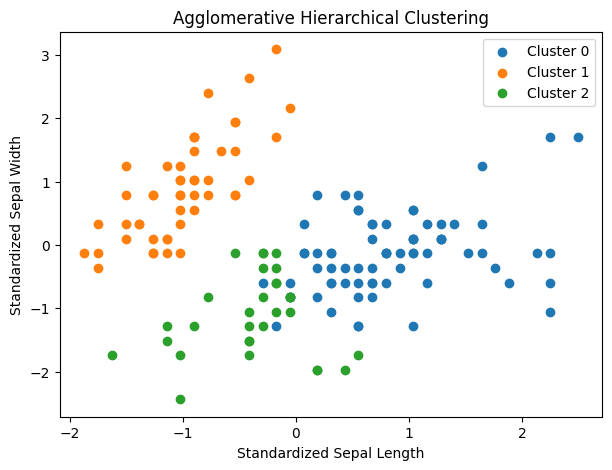

In [7]:
plt.figure(figsize=(7, 5))

for cluster in sorted(set(labels)):
    mask = labels == cluster

    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("Agglomerative Hierarchical Clustering")
plt.legend()
plt.show()